# 02 - Models, calibration and a cost-based threshold

Three questions, each with an explicit answer and an interval:

1. Does a complex model beat a simple one?
2. Are the probabilities trustworthy enough to act on?
3. Who should be contacted, and what is that worth?

The threshold is chosen on **out-of-fold** predictions from the training split and
then evaluated once on the held-out test split. Choosing it on the test set - as
the first version of this project did - makes the reported value optimistic.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.calibration import calibration_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from telco_churn.data import load_clean
from telco_churn.economics import Economics
from telco_churn.evaluate import (
    best_threshold, bootstrap_ci, bootstrap_capture_at_top, breakeven_probability,
    calibration_slope_intercept, calibration_table, capture_at_top,
    decision_curve, expected_net_value_curve, oracle_net_value_curve,
    paired_bootstrap_delta, summary_metrics, threshold_band,
)
from telco_churn.features import train_test
from telco_churn.model import build_pipeline
from telco_churn.targeting import compare_risk_vs_value, rank_by_value, segment_report

FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
ECON = Economics()
df = load_clean()
X_train, X_test, y_train, y_test = train_test(df, seed=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "logistic": build_pipeline("logistic", seed=42),
    "gradient boosting": build_pipeline("boosting", seed=42),
}
oof, fitted, probs = {}, {}, {}
for name, pipe in models.items():
    oof[name] = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    fitted[name] = pipe.fit(X_train, y_train)
    probs[name] = fitted[name].predict_proba(X_test)[:, 1]

print(f"{len(df):,} customers, {df.Churn.mean():.1%} churned; "
      f"train {len(X_train):,} / test {len(X_test):,}")

7,043 customers, 26.5% churned; train 5,634 / test 1,409


## 1. Simple vs sophisticated

A difference in point estimates is not evidence of a difference between models.
The paired bootstrap below resamples customers and scores both models on the same
rows, which is the right comparison for two models evaluated on one test set.

In [2]:
rows = []
for name, p in probs.items():
    m = summary_metrics(y_test, p)
    ci = bootstrap_ci(y_test, p, "roc_auc", seed=42)
    cap = bootstrap_capture_at_top(y_test, p, 0.2, seed=42)
    cal = calibration_slope_intercept(y_test, p)
    rows.append({
        "model": name,
        "test AUC": m["roc_auc"], "AUC 2.5%": ci["lo"], "AUC 97.5%": ci["hi"],
        "Brier": m["brier"], "log loss": m["log_loss"],
        "calibration slope": cal["slope"],
        "capture top 20%": cap["captured_share"],
    })
comparison = pd.DataFrame(rows).set_index("model")
delta = paired_bootstrap_delta(y_test, probs["logistic"], probs["gradient boosting"], "roc_auc")
print(f"Paired AUC difference (logistic - boosting): {delta['delta']:+.3f} "
      f"[{delta['lo']:+.3f}, {delta['hi']:+.3f}]; interval includes zero: {delta['includes_zero']}")
comparison.round(3)

Paired AUC difference (logistic - boosting): +0.005 [-0.001, +0.011]; interval includes zero: True


,test AUC,AUC 2.5%,AUC 97.5%,Brier,log loss,calibration slope,capture top 20%
model,,,,,,,
logistic,0.818,0.794,0.840,0.148,0.445,0.919,0.457
gradient boosting,0.813,0.788,0.836,0.150,0.450,0.881,0.455


The interval on the difference includes zero. The two models are not
distinguishable, so the simpler model is the better business choice: it is easier
to explain, audit and monitor, and it gives the same ranking.

## 2. Calibration: can we trust the probabilities?

Discrimination (AUC) says who is riskier. Calibration says whether "30%" really
means 30%, which is what a value calculation needs.

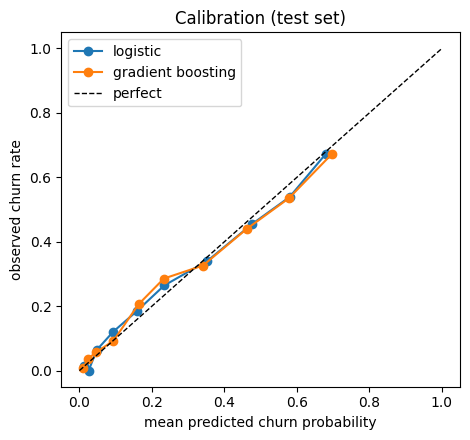

Logistic calibration slope 0.92 (1.0 = perfect), intercept -0.05


,n,predicted,observed
0,141,0.013,0.014
1,141,0.025,0.000
2,141,0.048,0.064
3,141,0.093,0.121
4,141,0.158,0.184
5,140,0.234,0.264
6,141,0.353,0.340
7,141,0.475,0.454
8,141,0.580,0.539
9,141,0.681,0.674


In [3]:
fig, ax = plt.subplots(figsize=(4.8, 4.5))
for name, p in probs.items():
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
ax.set_xlabel("mean predicted churn probability")
ax.set_ylabel("observed churn rate")
ax.legend()
ax.set_title("Calibration (test set)")
plt.tight_layout()
plt.savefig(FIG / "02_calibration.png", dpi=140)
plt.show()

cal = calibration_slope_intercept(y_test, probs["logistic"])
print(f"Logistic calibration slope {cal['slope']:.2f} (1.0 = perfect), intercept {cal['intercept']:+.2f}")
calibration_table(y_test, probs["logistic"]).round(3)

A slope near 1 and a diagonal calibration curve mean the probabilities can be
multiplied by money. The top decile is the one that matters commercially, so it is
worth checking that it is not systematically over-confident.

## 3. Where should the cut-off be?

Two curves, and the difference between them is the point:

- **Expected value** uses only the model's probabilities and the stated economics.
  This is what a campaign can expect.
- **Oracle value** uses the true churn label of every contacted customer. It is a
  ceiling that cannot be achieved in production, useful only to show how much
  ranking quality is left on the table.

With a constant save rate and a constant value per save, the expected-value rule
has an analytic cut-off: contact when `p > contact_cost / (save_rate * value_saved)`.

Break-even probability: 0.111
Policy: contact when p >= 0.110 -> 884 of 1409 customers
Expected net value: 23,036
Realised on the holdout (labels known): 22,840
Best retrospective threshold: 0.09 (23,010)
Contacting everyone would be worth: 19,646
Thresholds within 2% of the peak value: 0.06 to 0.17


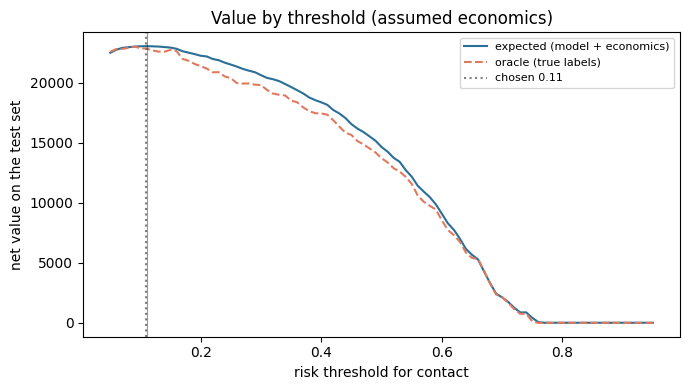

In [4]:
p = probs["logistic"]
expected = expected_net_value_curve(p, ECON.value_saved, ECON.contact_cost, ECON.save_rate)
oracle = oracle_net_value_curve(y_test, p, ECON.value_saved, ECON.contact_cost, ECON.save_rate)
best_expected = best_threshold(expected)
realised = oracle.iloc[(oracle.threshold - best_expected.threshold).abs().argmin()]
treat_all = expected_net_value_curve(
    p, ECON.value_saved, ECON.contact_cost, ECON.save_rate, thresholds=[0.0]
).net_value.iloc[0]
lo, hi = threshold_band(expected, tolerance=0.02)

print(f"Break-even probability: {ECON.breakeven_probability:.3f}")
print(f"Policy: contact when p >= {best_expected.threshold:.3f} -> {int(best_expected.contacted)} of {len(p)} customers")
print(f"Expected net value: {best_expected.net_value:,.0f}")
print(f"Realised on the holdout (labels known): {realised.net_value:,.0f}")
print(f"Best retrospective threshold: {oracle.loc[oracle.net_value.idxmax(), 'threshold']:.2f} "
      f"({oracle.net_value.max():,.0f})")
print(f"Contacting everyone would be worth: {treat_all:,.0f}")
print(f"Thresholds within 2% of the peak value: {lo:.2f} to {hi:.2f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(expected.threshold, expected.net_value, label="expected (model + economics)", color="#2a6f97")
ax.plot(oracle.threshold, oracle.net_value, label="oracle (true labels)", color="#e07a5f", ls="--")
ax.axvline(best_expected.threshold, color="grey", ls=":", label=f"chosen {best_expected.threshold:.2f}")
ax.axvline(ECON.breakeven_probability, color="black", lw=0.8, alpha=0.4)
ax.set_xlabel("risk threshold for contact")
ax.set_ylabel("net value on the test set")
ax.set_title("Value by threshold (assumed economics)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "02_net_value.png", dpi=140)
plt.show()

Both curves peak near the break-even probability, which is reassuring: the model
and the economics agree about where the margin disappears. The oracle curve is
higher at low thresholds because it can see which customers would actually leave;
that gap is the value of perfect information, not a forecast.

## 4. Decision-curve analysis

A single cost ratio is an assumption. Decision-curve analysis shows whether the
model beats "contact everyone" across a range of thresholds, without committing
to one number.

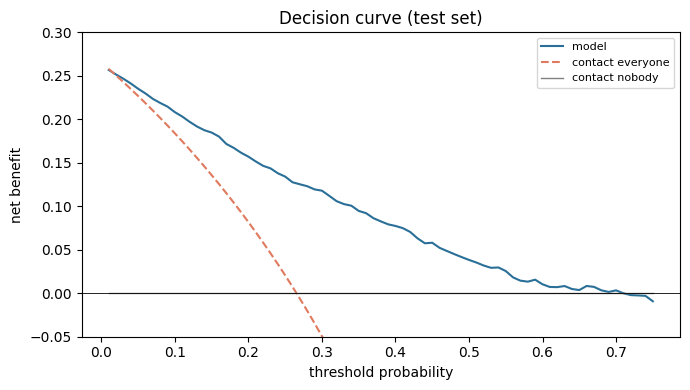

The model beats contacting everyone for thresholds between 0.02 and 0.75.


In [5]:
dc = decision_curve(y_test, p)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(dc.threshold, dc.model, label="model", color="#2a6f97")
ax.plot(dc.threshold, dc.treat_all, label="contact everyone", color="#e07a5f", ls="--")
ax.plot(dc.threshold, dc.treat_none, label="contact nobody", color="grey", lw=1)
ax.axhline(0, color="black", lw=0.6)
ax.set_ylim(-0.05, 0.30)
ax.set_xlabel("threshold probability")
ax.set_ylabel("net benefit")
ax.set_title("Decision curve (test set)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "02_decision_curve.png", dpi=140)
plt.show()

wins = dc.loc[dc.model > dc.treat_all, "threshold"]
print(f"The model beats contacting everyone for thresholds between "
      f"{wins.min():.2f} and {wins.max():.2f}.")

## 5. From risk to value: who is actually worth contacting?

Risk ranking assumes every customer is worth the same. They are not. If the value
at risk is proportional to the monthly bill, a slightly lower-risk customer on a
large bill can be worth more than a higher-risk customer on a small one.

The ranking below uses `p * margin * save_rate - contact_cost`, with margin
normalised so the average customer is worth the assumed `value_saved`.

Top  140: value ranking earns   10,463 vs risk ranking    9,863 (+600); 62% of names overlap
Top  280: value ranking earns   18,473 vs risk ranking   17,664 (+808); 84% of names overlap
Top  500: value ranking earns   26,324 vs risk ranking   25,363 (+961); 87% of names overlap


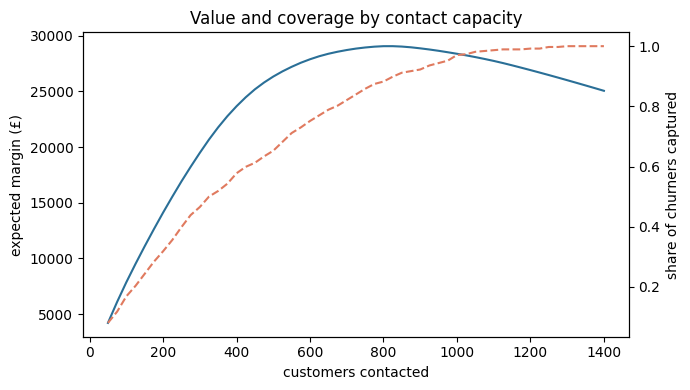


Contacting 500 customers: expected margin 26,324, mean risk 53.1% vs base rate 26.5%


,Contract,InternetService,customers,mean_risk,expected_value
0,Month-to-month,Fiber optic,417,0.563,24069.737
1,Month-to-month,DSL,43,0.462,1138.011
2,One year,Fiber optic,40,0.274,1116.514


In [6]:
frame = X_test.reset_index(drop=True).copy()
frame["churned"] = y_test.to_numpy()
ranking = rank_by_value(
    frame, p, ECON.relative_value(frame.MonthlyCharges),
    save_rate=ECON.save_rate, contact_cost=ECON.contact_cost,
)

for k in (140, 280, 500):
    c = compare_risk_vs_value(ranking, k)
    print(f"Top {k:4d}: value ranking earns {c['value_selected']:8,.0f} vs risk ranking "
          f"{c['value_risk_ranked']:8,.0f} ({c['value_gap']:+,.0f}); "
          f"{c['overlap_share']:.0%} of names overlap")

ks = np.arange(50, len(ranking) + 1, 25)
rows = []
for k in ks:
    q = ranking.head(k)
    rows.append({"k": k, "expected_value": q.expected_value.sum(),
                 "captured": q.churned.sum() / frame.churned.sum()})
sweep = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep.k, sweep.expected_value, color="#2a6f97", label="expected margin (£)")
ax.set_xlabel("customers contacted")
ax.set_ylabel("expected margin (£)")
ax2 = ax.twinx()
ax2.plot(sweep.k, sweep.captured, color="#e07a5f", ls="--", label="churners captured")
ax2.set_ylabel("share of churners captured")
ax.set_title("Value and coverage by contact capacity")
plt.tight_layout()
plt.savefig(FIG / "02_value_by_capacity.png", dpi=140)
plt.show()

capacity = 500
queue = ranking.head(capacity)
print(f"\nContacting {capacity} customers: expected margin {queue.expected_value.sum():,.0f}, "
      f"mean risk {queue.p_churn.mean():.1%} vs base rate {frame.churned.mean():.1%}")
segment_report(queue).round(3)

The value-ranked list is not the same as the risk-ranked list, and the gap grows
as the contact capacity shrinks. This is the difference between a churn model and
a retention policy: the model ranks people, the queue ranks *decisions*.

## 6. The economics are assumptions, so show the surface

The threshold is a function of three placeholders. A single value hides how much
the recommendation moves when they change.

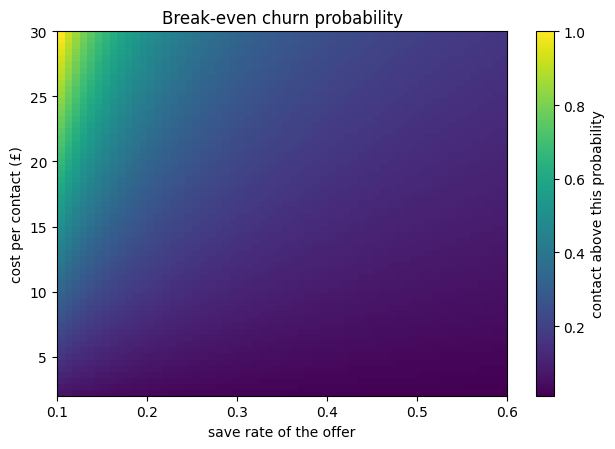

With the current assumptions the cut-off is 0.111.
Doubling the contact cost raises it to 0.222.


In [7]:
costs = np.linspace(2, 30, 60)
save_rates = np.linspace(0.10, 0.60, 60)
grid = np.array([[breakeven_probability(c, ECON.value_saved, s) for s in save_rates] for c in costs])

fig, ax = plt.subplots(figsize=(6.4, 4.6))
im = ax.imshow(grid, origin="lower", aspect="auto", cmap="viridis",
               extent=[save_rates.min(), save_rates.max(), costs.min(), costs.max()])
ax.set_xlabel("save rate of the offer")
ax.set_ylabel("cost per contact (£)")
ax.set_title("Break-even churn probability")
fig.colorbar(im, ax=ax, label="contact above this probability")
plt.tight_layout()
plt.savefig(FIG / "02_economics_sensitivity.png", dpi=140)
plt.show()

print(f"With the current assumptions the cut-off is {ECON.breakeven_probability:.3f}.")
print(f"Doubling the contact cost raises it to {breakeven_probability(2 * ECON.contact_cost, ECON.value_saved, ECON.save_rate):.3f}.")

## 7. Monitoring: drift and the retraining trigger

The model is a snapshot. Simulate a later population where prices rose 25% and
more customers moved to month-to-month contracts, and ask whether the documented
trigger fires.

In [8]:
from telco_churn.drift import drift_report, should_retrain

reference = X_train.reset_index(drop=True)
current = X_test.reset_index(drop=True).copy()
rng = np.random.default_rng(0)
current["MonthlyCharges"] = current["MonthlyCharges"] * 1.25
current.loc[rng.random(len(current)) < 0.35, "Contract"] = "Month-to-month"

report = drift_report(reference, current)
print(report.head(5).round(3).to_string(index=False))
print("\nRetrain?", should_retrain(report, brier_now=0.17, brier_ref=0.15))

       feature   psi  flag
MonthlyCharges 1.511  True
      Contract 0.091 False
  OnlineBackup 0.004 False
 MultipleLines 0.003 False
   StreamingTV 0.003 False

Retrain? (True, '1 features drifted (PSI above threshold)')


A single shift is a smoke test. Notebook 06 runs the same monitor month by month
and shows when the trigger would have fired in a slow drift scenario.

## Limitations

- The economics (`value_saved`, `contact_cost`, `save_rate`) are placeholders.
  Every money figure inherits them; replace them before quoting any number.
- The margin is assumed proportional to the monthly bill and normalised to the
  average. A real business would use expected lifetime margin, which needs
  survival and expansion/contraction assumptions.
- A model ranks risk; it does not estimate the effect of an offer. The save rate
  is assumed constant across customers, which is exactly the assumption uplift
  modelling relaxes (notebook 05).
- Churn is a single snapshot outcome; notebook 03 treats time-to-event properly.